# Is Cooling Required While Charging?
<rb>Determine cooling requirements for cells while charging

### Known Parameters:
* Max Charging Current from Elcon: 14 A

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Constant Parameters
max_charge_i = 14           # A - max charging current

cell_Ah = 2.8               # Ah - cell max capacity
n_p = 5                     # Number of cells in parallel
n_s = 140                   # Number of cells in series
pack_Ah = cell_Ah * n_p     # Ah - pack capacity

charge_CRate = max_charge_i / pack_Ah   # CRate
i_per_cell = max_charge_i / n_p         # A - current per cell

print(i_per_cell)

2.8


The resulting C Rate of the charging process is 1 C. Which is within the acceptable charging current range. We will expect the charging process to take one hour. I need to verify whether the pack charges at 14A for an entire hour and then sees current drop as it charges at constant voltage...?

Ok, so as per Battery University (https://batteryuniversity.com/article/bu-409-charging-lithium-ion#google_vignette), the CC-CV profile charges the battery up to its full voltage within one hour at 1C rate. Then, it trickle charges the battery until it reaches its full capacity, which can take another hour or two.

Ok - so this tells us that we need to test the max current condition for 1 hour (at least at the 1C rate we expect as a maximum charging current).

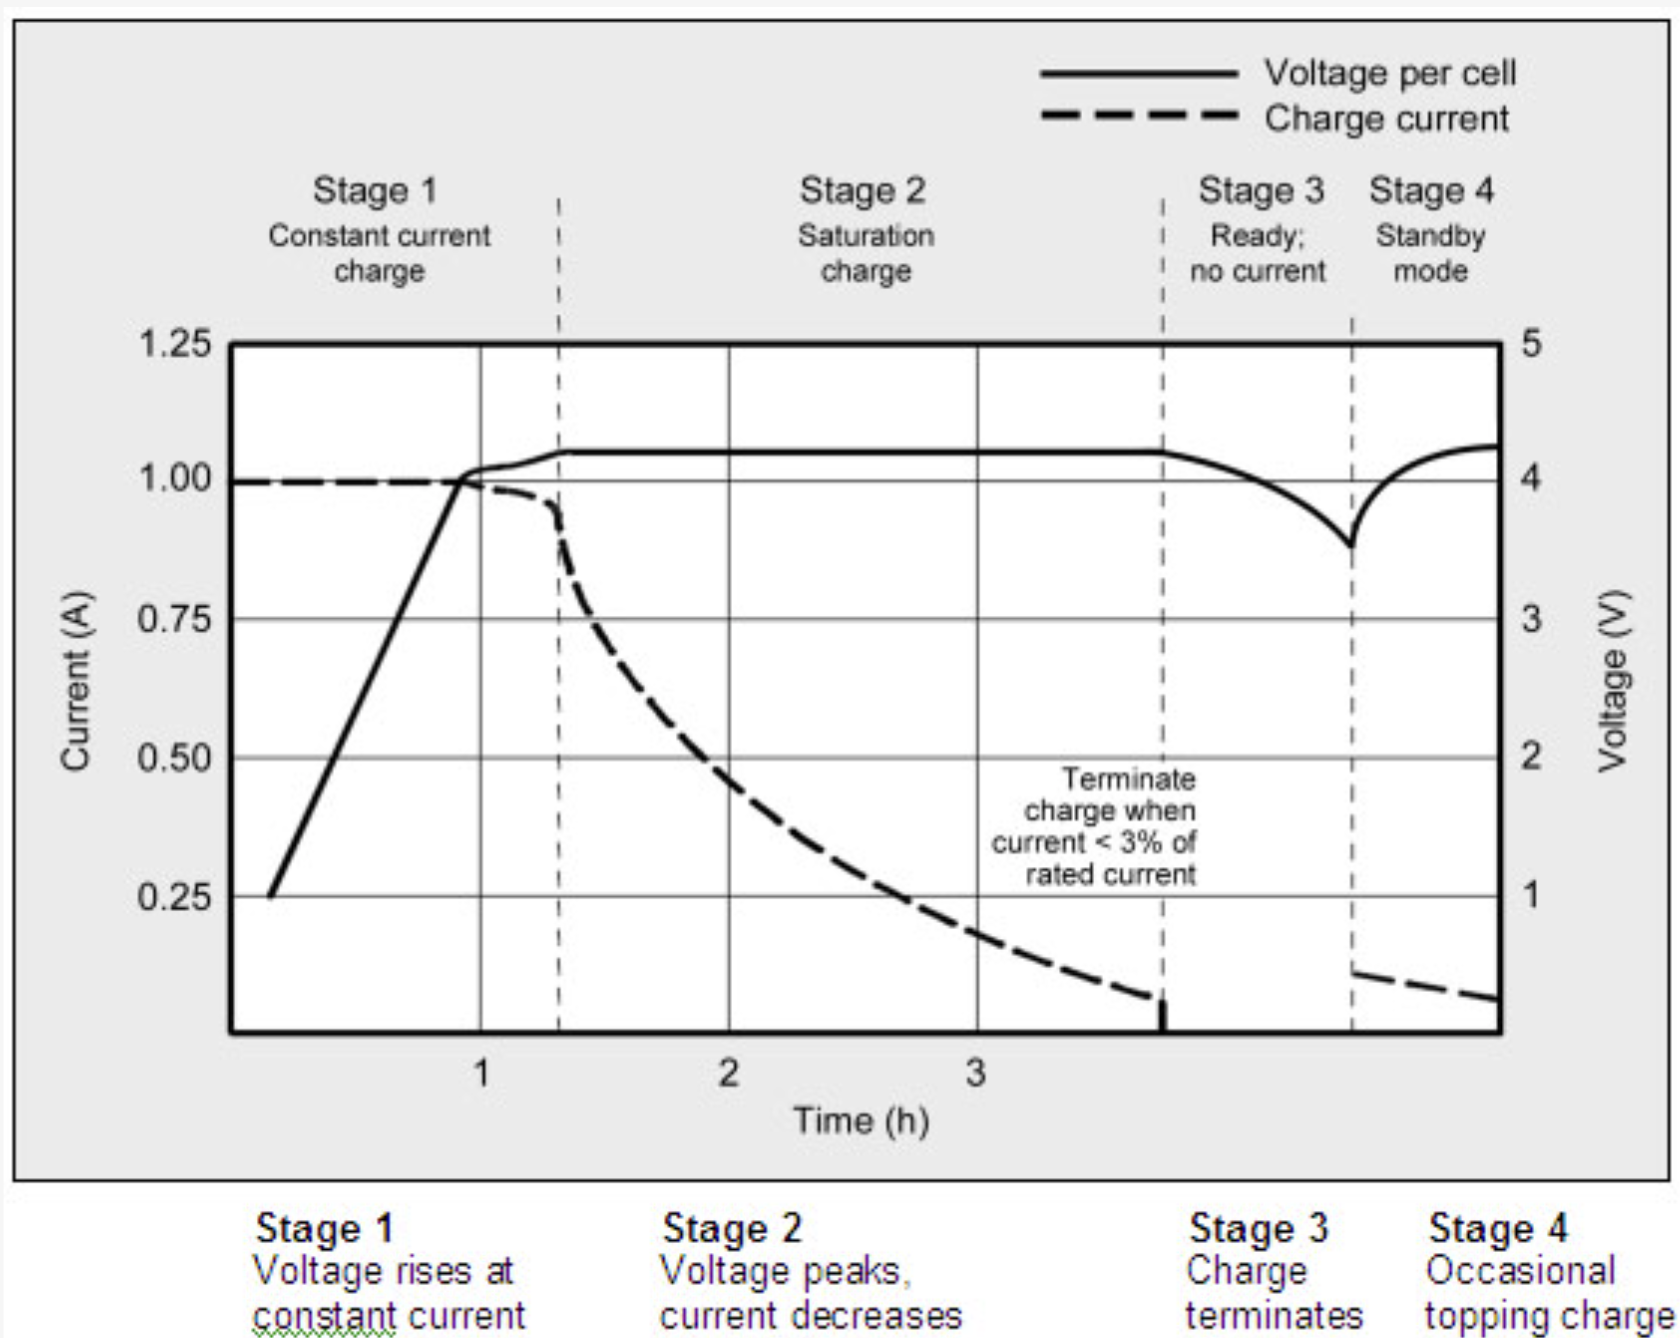
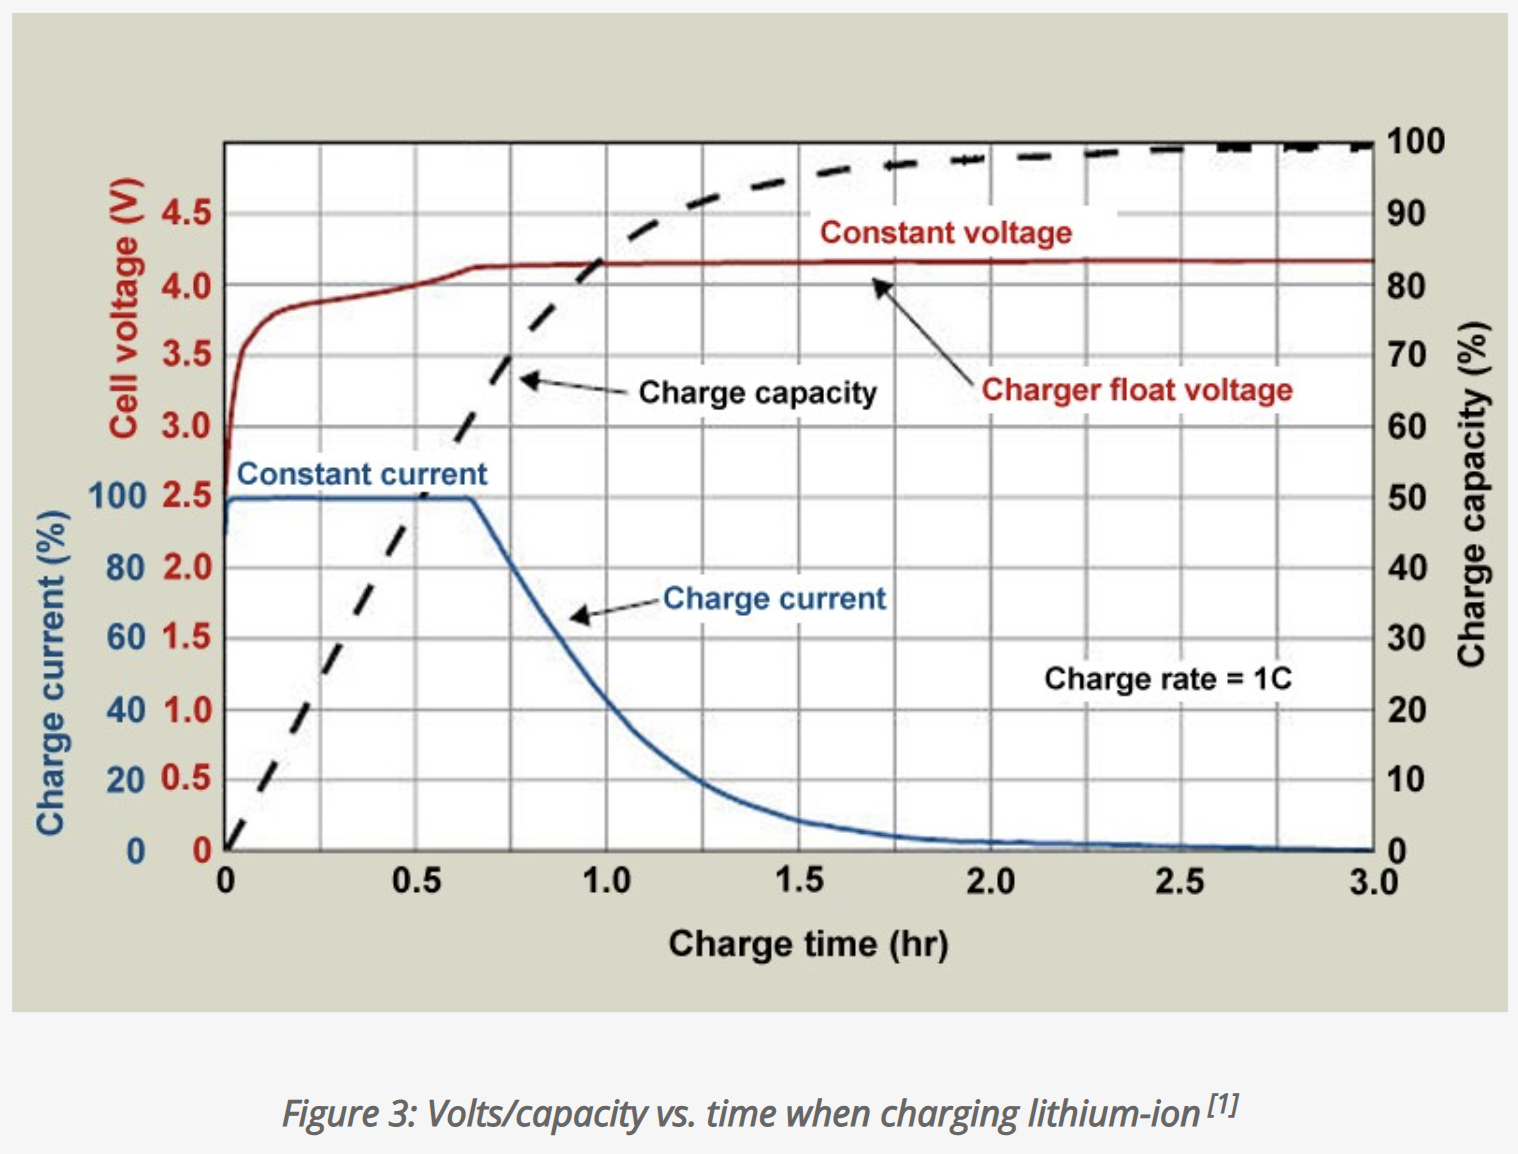

Now I need to determine what the temperature of the cells will be with no cooling during the charging process.

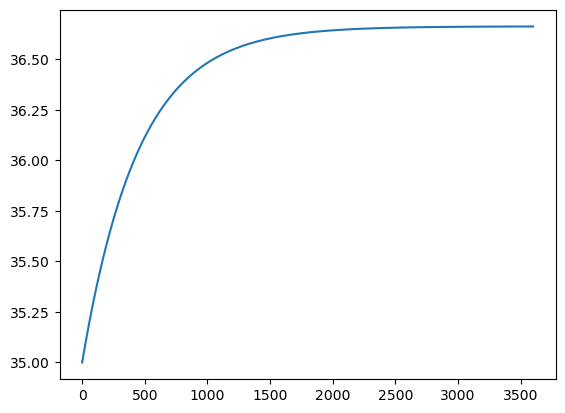

In [3]:
### CONSTANTS
# Time:
hrs = 1                     # hrs - charging time (total)
total_time = hrs * 60 * 60  # secs - charging time (total)
dt = 0.1                    # secs - delta time
num_intervals = int(total_time / dt)

# Thermals:
# htc = 0                     # W/m2K - convective heat transfer coefficient
# A_conv = 0                  # m2 - convective heat transfer area

# Thermals Plus: https://ubcformulaelectric.atlassian.net/wiki/spaces/UFE/pages/414646339/Accumulator+-+TMS+-+V3.0+Thermal+Benchmarking
# Both have been scaled from 26650 to 18650
thermal_resistance_in = 2.21714     # K/W - maximum measured case
thermal_resistance_out = 10.6106    # K/W - case with no fans

cell_mass = 0.046               # kg - cell mass
DCIR = 0.02                     # Ohms - DC internal resistance of Molicel P28A (https://www.molicel.com/wp-content/uploads/INR18650P28A-V1-80093.pdf)
Qgen = i_per_cell**2 * DCIR     # W - heat generated
air_temp = 35                   # C - air ambient temperature (maximum for competition)
battery_heat_capacity = 35.098      # J/K (Calculated from Simulation - tbh not sure what this is referring to)

# EMPTY ARRAYS
time = np.zeros(num_intervals)                   # s - time vector
temp = np.zeros(num_intervals)                   # C - temperature vector
Qout = np.zeros(num_intervals)                   # W - rate of heat transfer out of cells
Net_Q = np.zeros(num_intervals)                  # W - net heat out

temp[0] = air_temp

for i in range(0, num_intervals-1):
    # NOTE TO SELF - this is from dynFunctions.py
    # Look at my notes on confluence (https://ubcformulaelectric.atlassian.net/wiki/spaces/UFE/pages/edit-v2/405438472)
    # for how I came across this formula (and to verify that it is correct)

    # NOTE TO SELF:
    # Look at my notes on confluence (https://ubcformulaelectric.atlassian.net/wiki/spaces/UFE/pages/edit-v2/405438472)
    # for how I came across this formula (and to verify that it is correct)
    air_temp_K = air_temp + 273.15      # Convert to K from C

    battery_temp_K = (((Qgen * thermal_resistance_out + air_temp_K) * dt
                    + (temp[i] + 273.15) * battery_heat_capacity * (thermal_resistance_in + thermal_resistance_out))
                    / (battery_heat_capacity * (thermal_resistance_in + thermal_resistance_out) + dt))
    
    temp[i+1] = battery_temp_K - 273.15     # Convert back to C from K

    # Calculate net heat generation rate (Qgen - Qtransferred)
    Qout[i] = 1 / thermal_resistance_out * (temp[i] - air_temp)
    Net_Q[i] = Qgen - Qout[i]

    # update the time
    time[i+1] = time[i] + dt

# Plot results
plt.plot(time, temp)

In [4]:
Qgen_pack_operation = 1.62
Ratio = Qgen / Qgen_pack_operation
print("Qgen during charging is %.3f %% of the heat generation during racing" % (Ratio * 100))

Qgen during charging is 9.679 % of the heat generation during racing


For charging, we will be generating 0.056 W of heat. In comparison, for CFD simulations done on the half pack, we assumed a rate of heat generation of 1.62 W. With 1.62 W, we saw the following temperature vs fan flow rate curve:

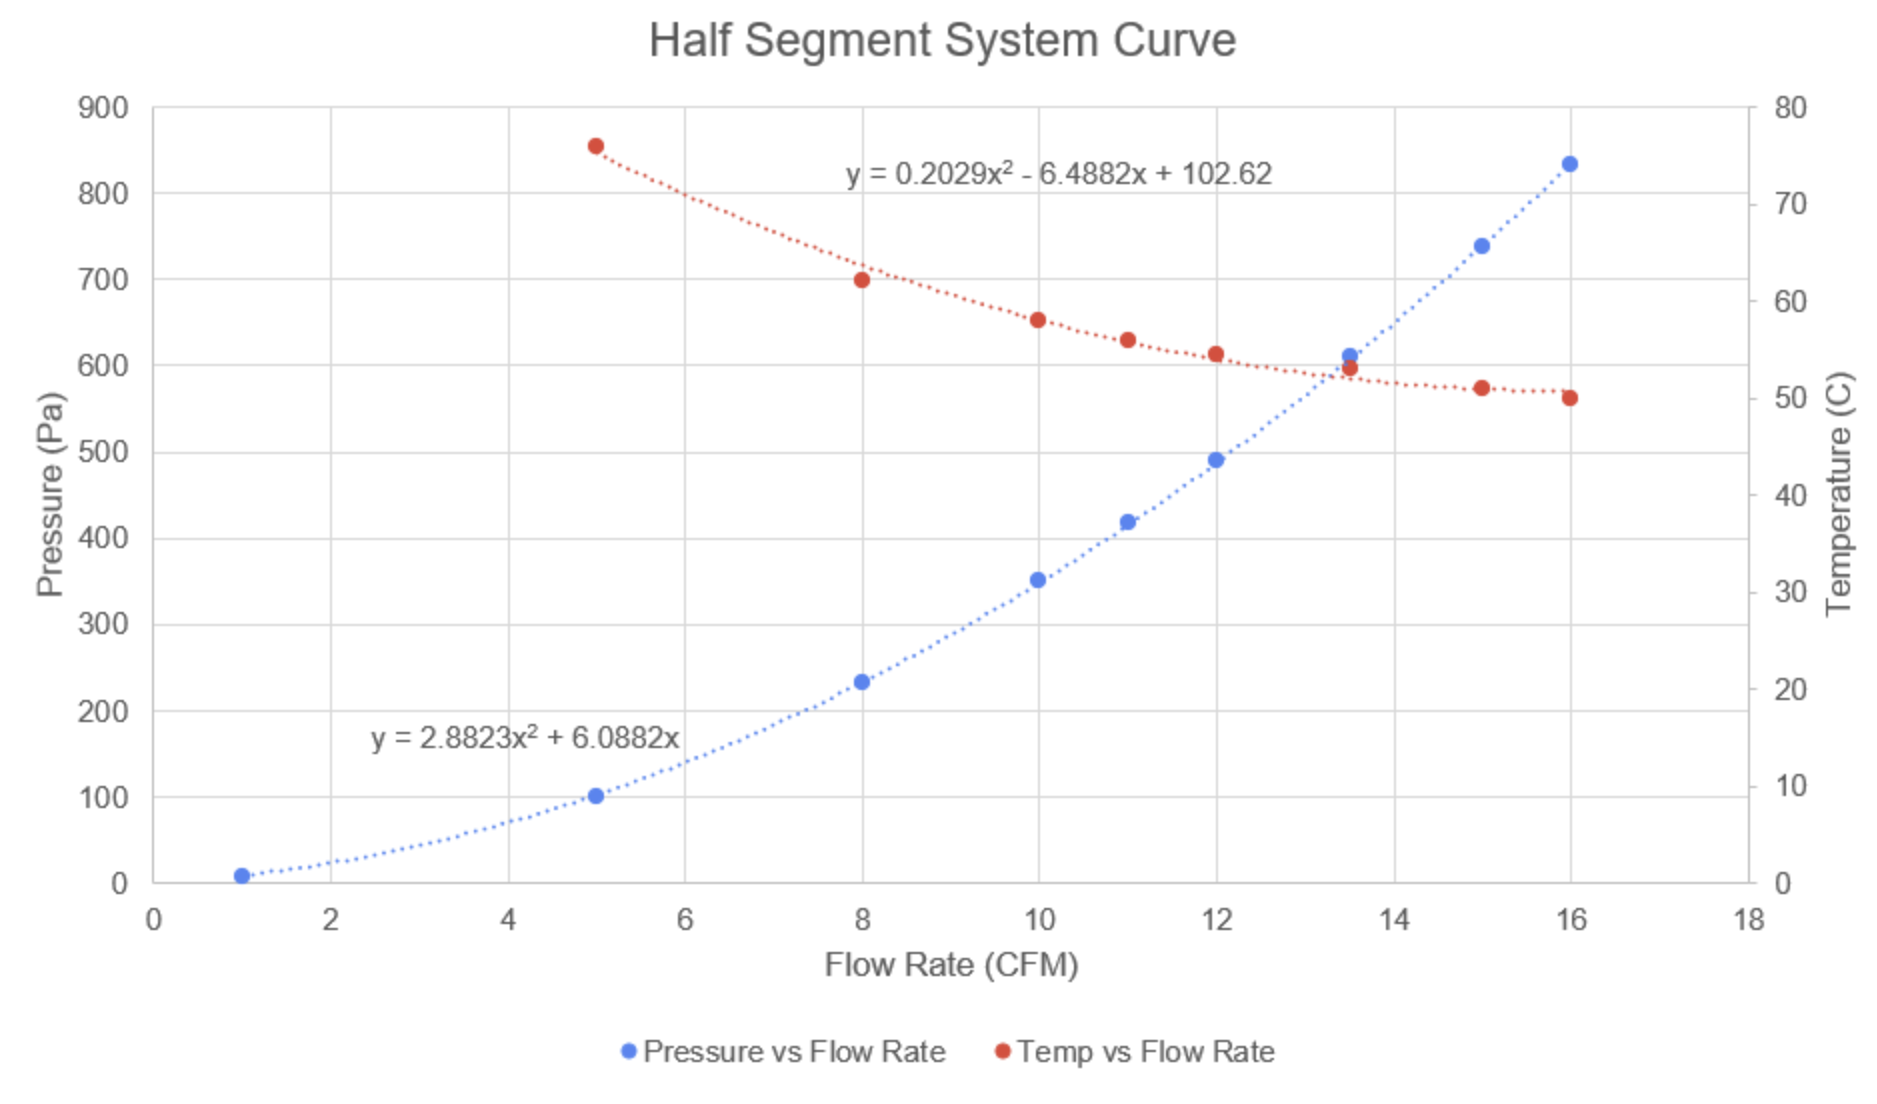

### Redo on Jan 18, 2025

Current per cell:  2.8


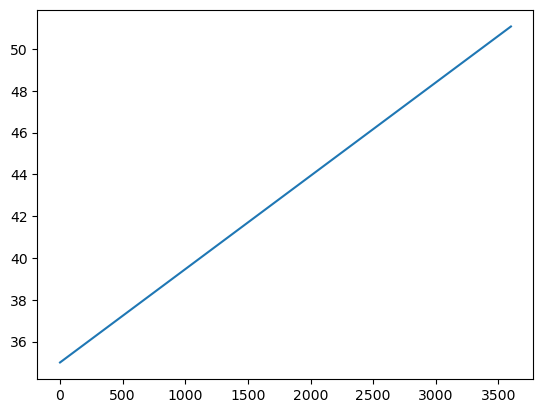

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Constant Parameters
max_charge_i = 14           # A - max charging current

cell_Ah = 2.8               # Ah - cell max capacity
n_p = 5                     # Number of cells in parallel
n_s = 140                   # Number of cells in series
pack_Ah = cell_Ah * n_p     # Ah - pack capacity

charge_CRate = max_charge_i / pack_Ah   # CRate
i_per_cell = max_charge_i / n_p         # A - current per cell

print("Current per cell: ", i_per_cell)

#### 
### CONSTANTS
# Time:
hrs = 1                     # hrs - charging time (total)
total_time = hrs * 60 * 60  # secs - charging time (total)
dt = 0.1                    # secs - delta time
num_intervals = int(total_time / dt)

# Thermals:
# htc = 0                     # W/m2K - convective heat transfer coefficient
# A_conv = 0                  # m2 - convective heat transfer area

# # Thermals Plus: https://ubcformulaelectric.atlassian.net/wiki/spaces/UFE/pages/414646339/Accumulator+-+TMS+-+V3.0+Thermal+Benchmarking
# # Both have been scaled from 26650 to 18650
# thermal_resistance_in = 2.21714     # K/W - maximum measured case
# thermal_resistance_out = 10.6106    # K/W - case with no fans

cell_mass = 0.046               # kg - cell mass
DCIR = 0.02                     # Ohms - DC internal resistance of Molicel P28A (https://www.molicel.com/wp-content/uploads/INR18650P28A-V1-80093.pdf)
Qgen = i_per_cell**2 * DCIR     # W - heat generated
air_temp = 35                   # C - air ambient temperature (maximum for competition)
battery_heat_capacity = 35.098      # J/K (Calculated from Simulation - tbh not sure what this is referring to)

# EMPTY ARRAYS
time = np.zeros(num_intervals)                   # s - time vector
temp = np.zeros(num_intervals)                   # C - temperature vector
Qout = np.zeros(num_intervals)                   # W - rate of heat transfer out of cells
Net_Q = np.zeros(num_intervals)                  # W - net heat out

temp[0] = air_temp

for i in range(0, num_intervals-1):

    # # NOTE TO SELF:
    # # Look at my notes on confluence (https://ubcformulaelectric.atlassian.net/wiki/spaces/UFE/pages/edit-v2/405438472)
    # # for how I came across this formula (and to verify that it is correct)
    # air_temp_K = air_temp + 273.15      # Convert to K from C

    temp[i+1] = Qgen / (battery_heat_capacity / dt) + temp[i]

    # Calculate net heat generation rate (Qgen - Qtransferred)
    Qout[i] = 0 #1 / thermal_resistance_out * (temp[i] - air_temp)
    Net_Q[i] = Qgen - Qout[i]

    # update the time
    time[i+1] = time[i] + dt

# Plot results
plt.plot(time, temp)